# pr2 · Linear systems stability: condition number of a matrix
Backward error formula: $\dfrac{\|\delta x\|}{\|\hat x\|} \le \kappa(A)\left(\dfrac{\|\delta A\|}{\|A\|} + \dfrac{\|\delta b\|}{\|A\|\|\hat x\|}\right)$

In [1]:
import numpy as np, scipy.linalg as sla, pandas as pd, matplotlib.pyplot as plt
from time import perf_counter
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
eps = np.finfo(float).eps
print(f"eps_machine = {eps:.3e}")

eps_machine = 2.220e-16


## 1(a) · Vandermonde, $\alpha_j = 1 - 2(j-1)/(n-1)$

In [2]:
def vandermonde(n):
    alpha = 1 - 2 * np.arange(n) / (n - 1)
    return alpha[None, :] ** np.arange(n)[:, None]       # row i = alpha^i

ns = np.arange(2, 51)
kV = np.array([np.linalg.cond(vandermonde(n)) for n in ns])
fit = np.polyfit(ns[ns <= 35], np.log(kV[ns <= 35]), 1)
print(f"fit (n <= 35):  kappa_2(V_n) ~ {np.exp(fit[1]):.2f} * e^({fit[0]:.3f} n)   (≈ {np.exp(fit[0]):.2f}^n)")
print(pd.DataFrame({"n": ns, "kappa_2": kV}).set_index("n").T[[5, 10, 20, 30, 40, 50]].map("{:.2e}".format).to_string())

fit (n <= 35):  kappa_2(V_n) ~ 0.09 * e^(1.098 n)   (≈ 3.00^n)
n              5         10        20        30        40        50
kappa_2  2.35e+01  4.63e+03  2.72e+08  1.84e+13  3.40e+18  4.71e+18


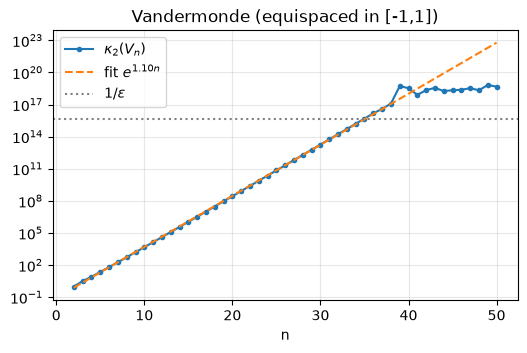

In [3]:
plt.figure(figsize=(6, 3.5))
plt.semilogy(ns, kV, "o-", ms=3, label=r"$\kappa_2(V_n)$")
plt.semilogy(ns, np.exp(np.polyval(fit, ns)), "--", label=f"fit $e^{{{fit[0]:.2f}n}}$")
plt.axhline(1 / eps, color="gray", ls=":", label=r"$1/\epsilon$")
plt.xlabel("n"); plt.legend(); plt.grid(alpha=.3); plt.title("Vandermonde (equispaced in [-1,1])"); plt.show()

Exponential growth. Beyond $\kappa \approx 1/\epsilon$ the computed value is no longer reliable (the matrix is numerically singular).

## 1(b) · Hilbert matrices, Szegö: $\kappa_2(H_n) \sim e^{3.5n}$

In [4]:
ns_h = np.arange(1, 16)
kH = np.array([np.linalg.cond(sla.hilbert(n)) for n in ns_h])
slope = np.polyfit(ns_h[2:12], np.log(kH[2:12]), 1)[0]
print(f"fitted growth rate (3 <= n <= 12): {slope:.3f}   (Szegö: 3.5)\n")
print(pd.DataFrame({"n": ns_h, "kappa_2(H_n)": kH, "e^{3.5n}": np.exp(3.5 * ns_h),
                    "log(kappa)/n": np.log(kH) / ns_h}).to_string(index=False, float_format="{:.3e}".format))

fitted growth rate (3 <= n <= 12): 3.463   (Szegö: 3.5)

 n  kappa_2(H_n)  e^{3.5n}  log(kappa)/n
 1     1.000e+00 3.312e+01     0.000e+00
 2     1.928e+01 1.097e+03     1.480e+00
 3     5.241e+02 3.632e+04     2.087e+00
 4     1.551e+04 1.203e+06     2.412e+00
 5     4.766e+05 3.982e+07     2.615e+00
 6     1.495e+07 1.319e+09     2.753e+00
 7     4.754e+08 4.367e+10     2.854e+00
 8     1.526e+10 1.446e+12     2.931e+00
 9     4.932e+11 4.789e+13     2.992e+00
10     1.602e+13 1.586e+15     3.041e+00
11     5.223e+14 5.252e+16     3.081e+00
12     1.761e+16 1.739e+18     3.117e+00
13     3.191e+18 5.760e+19     3.277e+00
14     9.276e+17 1.907e+21     2.955e+00
15     3.676e+17 6.316e+22     2.696e+00


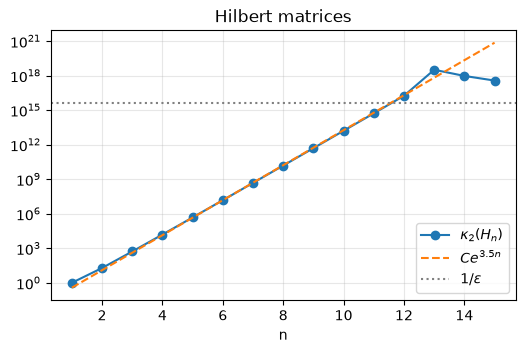

In [5]:
plt.figure(figsize=(6, 3.5))
plt.semilogy(ns_h, kH, "o-", label=r"$\kappa_2(H_n)$")
plt.semilogy(ns_h, np.exp(3.5 * ns_h) * kH[5] / np.exp(3.5 * 6), "--", label=r"$C e^{3.5n}$")
plt.axhline(1 / eps, color="gray", ls=":", label=r"$1/\epsilon$")
plt.xlabel("n"); plt.legend(); plt.grid(alpha=.3); plt.title("Hilbert matrices"); plt.show()

Rate ≈ 3.5 until $\kappa \sim 10^{17}$ ($n \approx 12$); after that `cond` saturates due to rounding.

## 2 · Frank matrix: condition number vs. accuracy

In [6]:
def frank(n):
    i, j = np.indices((n, n)) + 1
    return np.where(j >= i, n + 1 - j, np.where(j == i - 1, n + 1 - i, 0)).astype(float)

print(frank(5))

[[5. 4. 3. 2. 1.]
 [4. 4. 3. 2. 1.]
 [0. 3. 3. 2. 1.]
 [0. 0. 2. 2. 1.]
 [0. 0. 0. 1. 1.]]


In [7]:
rows = []
for n in range(2, 25):
    A = frank(n); x0 = np.ones(n); b = A @ x0
    x = np.linalg.solve(A, b)                                   # GEPP (LAPACK)
    k2 = np.linalg.cond(A)
    rows.append([n, k2, eps * k2, np.linalg.norm(x - x0) / np.linalg.norm(x0)])
df = pd.DataFrame(rows, columns=["n", "k2(A)", "eps*k2(A)", "e_rel(x)"]).set_index("n")
df.style.format("{:.2e}")

LinAlgError: Singular matrix

In [ ]:
plt.figure(figsize=(6, 3.5))
plt.semilogy(df.index, df["eps*k2(A)"], "o-", label=r"$\epsilon\,\kappa_2(A)$ (bound)")
plt.semilogy(df.index, df["e_rel(x)"], "s-", label=r"$e_{rel}(x)$")
plt.xlabel("n"); plt.legend(); plt.grid(alpha=.3); plt.title("Frank matrix"); plt.show()

$\delta b \sim \epsilon\|b\|$ and GEPP is backward stable ($\|\delta A\| \sim \epsilon\|A\|$), so the formula gives $e_{rel} \lesssim \epsilon\,\kappa_2(A)$.
The error grows with $\kappa_2$ and stays below (and typically close to) that bound: we lose about $\log_{10}\kappa_2$ digits.

## 3 · Moral: don't compute $A^{-1}$
Random $A = Q^tDQ$ with $D = \mathrm{diag}(\alpha,1,\dots,1)$, $\kappa_2(A) = \alpha = \epsilon^{-1/2}$. Backward error $\eta_{A,b} = \dfrac{\|r\|}{\|A\|\|x\|+\|b\|}$.

In [ ]:
def rand_cond(n, alpha):
    Q, _ = np.linalg.qr(rng.standard_normal((n, n)))
    D = np.ones(n); D[0] = alpha
    return Q.T @ (D[:, None] * Q)

def eta(A, x, b):
    return np.linalg.norm(A @ x - b) / (np.linalg.norm(A, 2) * np.linalg.norm(x) + np.linalg.norm(b))

def solve_inv(A, b): return sla.inv(A) @ b                     # inverse computed via GEPP (getrf + getri)
def solve_lu(A, b):  return sla.lu_solve(sla.lu_factor(A), b)  # GEPP

alpha = eps ** -0.5
print(f"kappa_2(A) = eps^-1/2 = {alpha:.2e}\n")
rows = []
for n, N in [(25, 50), (50, 10_000)]:
    e_inv, e_lu = [], []
    for _ in range(N):
        A = rand_cond(n, alpha); x = rng.standard_normal(n); b = A @ x
        e_inv.append(eta(A, solve_inv(A, b), b)); e_lu.append(eta(A, solve_lu(A, b), b))
    for name, e in [("A^-1 b", e_inv), ("GEPP", e_lu)]:
        rows.append([f"n={n}, {N} systems", name, min(e), np.median(e), max(e)])
pd.DataFrame(rows, columns=["experiment", "method", "min eta", "median eta", "max eta"]) \
  .set_index(["experiment", "method"]).style.format("{:.2e}")

GEPP gives $\eta \approx \epsilon$ (backward stable). The inverse method has backward errors orders of magnitude larger (∝ $\kappa(A)\epsilon$).

Timing (1000 systems per $n$):

In [ ]:
rows = []
for n in range(10, 101, 10):
    As = [rand_cond(n, alpha) for _ in range(1000)]; bs = rng.standard_normal((1000, n))
    t = perf_counter(); [solve_inv(A, b) for A, b in zip(As, bs)]; t_inv = perf_counter() - t
    t = perf_counter(); [solve_lu(A, b)  for A, b in zip(As, bs)]; t_lu  = perf_counter() - t
    rows.append([n, t_inv, t_lu, t_inv / t_lu])
for n in [500, 1000, 2000]:                                  # large n: flop count dominates
    A = rand_cond(n, alpha); b = rng.standard_normal(n)
    t = perf_counter(); solve_inv(A, b); t_inv = perf_counter() - t
    t = perf_counter(); solve_lu(A, b);  t_lu  = perf_counter() - t
    rows.append([n, t_inv, t_lu, t_inv / t_lu])
dt = pd.DataFrame(rows, columns=["n", "time A^-1 [s]", "time GEPP [s]", "ratio"]).set_index("n")
dt.style.format({"time A^-1 [s]": "{:.4f}", "time GEPP [s]": "{:.4f}", "ratio": "{:.2f}"})

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
small = dt.loc[:100]
ax[0].plot(small.index, small["time A^-1 [s]"], "o-", label="$A^{-1}b$")
ax[0].plot(small.index, small["time GEPP [s]"], "s-", label="GEPP")
ax[0].set(xlabel="n", ylabel="time for 1000 systems [s]"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(dt.index, dt["ratio"], "o-"); ax[1].axhline(3, ls="--", color="gray", label="flop ratio 3")
ax[1].set(xscale="log", xlabel="n", ylabel="time ratio inv / GEPP"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

For small $n$ call overhead hides the difference; as $n$ grows the ratio tends to the theoretical $2n^3 / (2n^3/3) = 3$.

## 4 · Estimating $\kappa_1(A)$ — Hager's algorithm

In [ ]:
def hager(Bx, BTx, n, maxit=10):
    '''Lower bound of ||B||_1 using only products with B and B^T.'''
    x = np.full(n, 1 / n)
    for it in range(1, maxit + 1):
        w = Bx(x)
        z = BTx(np.where(w >= 0, 1.0, -1.0))
        if np.max(np.abs(z)) <= z @ x:
            return np.linalg.norm(w, 1), it
        x = np.zeros(n); x[np.argmax(np.abs(z))] = 1.0
    return np.linalg.norm(w, 1), it

# (a) check on random matrices
rows = []
for n in [5, 20, 100, 500]:
    B = rng.standard_normal((n, n))
    est, it = hager(lambda x: B @ x, lambda y: B.T @ y, n)
    rows.append([n, est, np.linalg.norm(B, 1), est / np.linalg.norm(B, 1), it])
pd.DataFrame(rows, columns=["n", "estimate", "||B||_1", "ratio", "iterations"]).set_index("n").round(4)

In [ ]:
# (b) estimate ||A^-1||_1 solving A w = x and A^T z = zeta with one LU factorization
def cond1_est(A):
    lu = sla.lu_factor(A); n = A.shape[0]
    w, it = hager(lambda x: sla.lu_solve(lu, x), lambda y: sla.lu_solve(lu, y, trans=1), n)
    return np.linalg.norm(A, 1) * w, it

def rand_cond_svd(n, k):
    '''A = U diag(s) V^T with singular values log-spaced from 1 to 1/k  (kappa_2 = k).'''
    U, _ = np.linalg.qr(rng.standard_normal((n, n))); V, _ = np.linalg.qr(rng.standard_normal((n, n)))
    return (U * np.logspace(0, -np.log10(k), n)) @ V.T

res = []
for _ in range(1000):
    n = rng.integers(10, 91); k2 = 10 ** rng.uniform(3, 16)
    A = rand_cond_svd(n, k2)
    est, it = cond1_est(A)
    exact = np.linalg.norm(A, 1) * np.linalg.norm(np.linalg.inv(A), 1)
    res.append([n, k2, est / exact, it])
res = pd.DataFrame(res, columns=["n", "k2", "ratio", "iterations"])
print(f"ratio estimate/exact over 1000 matrices:")
print(f"  min {res.ratio.min():.3f} | mean {res.ratio.mean():.3f} | max {res.ratio.max():.3f}")
print(f"  exact (ratio > 0.999): {(res.ratio > 0.999).mean():.1%}   within factor 2: {(res.ratio > 0.5).mean():.1%}")
print(f"  iterations: {res.iterations.value_counts().sort_index().to_dict()}")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(res.ratio, bins=40); ax[0].set(xlabel="estimated / exact $\\kappa_1$", ylabel="count")
ax[1].scatter(res.k2, res.ratio, s=6, c=res.n, cmap="viridis"); ax[1].set(xscale="log", xlabel=r"$\kappa_2(A)$", ylabel="ratio")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

The estimate is always a lower bound, exact in most cases and within a small factor otherwise, with ~2 iterations (each $O(n^2)$ after the LU) instead of computing $A^{-1}$.